# TP4 – Deep Learning & Reinforcement Learning
## Classification multi-classe avec Fashion-MNIST (MLP + Régularisation)


---
##  Imports

In [17]:
# Calcul numérique
import numpy as np
# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
# Dataset
from tensorflow.keras.datasets import fashion_mnist
# Construction du réseau de neurones
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
# Régularisation
from tensorflow.keras.regularizers import l1, l2, l1_l2
# Callback Early Stopping
from tensorflow.keras.callbacks import EarlyStopping
# Préparation des données
from sklearn.model_selection import train_test_split
# Évaluation du modèle
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
# Tableau comparatif
import pandas as pd
import numpy as np
import tensorflow as tf
import random

seed = 42

np.random.seed(seed)
tf.random.set_seed(seed)
random.seed(seed)

print('Imports réussis !')

Imports réussis !


---
## Q1 – Charger et explorer le dataset Fashion-MNIST

In [18]:
# Q1 - Charger et explorer le dataset Fashion MNIST
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Afficher les dimensions
print('Forme de X_train :', X_train.shape)
print('Forme de y_train :', y_train.shape)
print('Forme de X_test  :', X_test.shape)
print('Forme de y_test  :', y_test.shape)



Forme de X_train : (60000, 28, 28)
Forme de y_train : (60000,)
Forme de X_test  : (10000, 28, 28)
Forme de y_test  : (10000,)


---
## Q2 – Préparation des données

In [19]:
# Q2 - Préparation des données pour le MLP

# 1) Mise à l'échelle des pixels entre 0 et 1
X_train = X_train.astype('float32') / 255
X_test  = X_test.astype('float32')  / 255

# 2) Transformation des images 28x28 en vecteurs de taille 784
X_train = X_train.reshape(X_train.shape[0], 28 * 28)
X_test  = X_test.reshape(X_test.shape[0],   28 * 28)

# 3) Création d'un ensemble de validation (20% de l'ensemble d'entraînement)
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Vérification des nouvelles dimensions
print('Forme de X_train_final :', X_train_final.shape)
print('Forme de y_train_final :', y_train_final.shape)
print('Forme de X_val         :', X_val.shape)
print('Forme de y_val         :', y_val.shape)
print('Forme de X_test        :', X_test.shape)
print('Forme de y_test        :', y_test.shape)

Forme de X_train_final : (48000, 784)
Forme de y_train_final : (48000,)
Forme de X_val         : (12000, 784)
Forme de y_val         : (12000,)
Forme de X_test        : (10000, 784)
Forme de y_test        : (10000,)


---
## Q3 – Construction du modèle de base (sans régularisation)

In [20]:
# Q3 - Construction du modèle de base sans régularisation
model_baseline = Sequential([
    Dense(256, activation='relu', input_shape=(784,)),
    Dense(128, activation='relu'),
    Dense(64,  activation='relu'),
    Dense(10,  activation='softmax')
])

# Compilation du modèle
model_baseline.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Affichage du résumé du modèle
model_baseline.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

---
## Q4 – Entraînement du modèle de base

In [21]:
# Q4 - Entraînement du modèle de base
history_baseline = model_baseline.fit(
    X_train_final, y_train_final,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=128,
    verbose=1
)

Epoch 1/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8066 - loss: 0.5481 - val_accuracy: 0.8542 - val_loss: 0.4088
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8575 - loss: 0.3897 - val_accuracy: 0.8521 - val_loss: 0.3983
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8732 - loss: 0.3438 - val_accuracy: 0.8720 - val_loss: 0.3540
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8840 - loss: 0.3147 - val_accuracy: 0.8756 - val_loss: 0.3439
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8900 - loss: 0.2928 - val_accuracy: 0.8826 - val_loss: 0.3243
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8975 - loss: 0.2752 - val_accuracy: 0.8845 - val_loss: 0.3287
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9014 - loss: 0.2618 - val_accuracy: 0.8864 - val_loss: 0.3276
Epoch 8/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9057 - loss: 0.2506 - val_accuracy: 

---
## Q5 – Analyse des performances du modèle de base

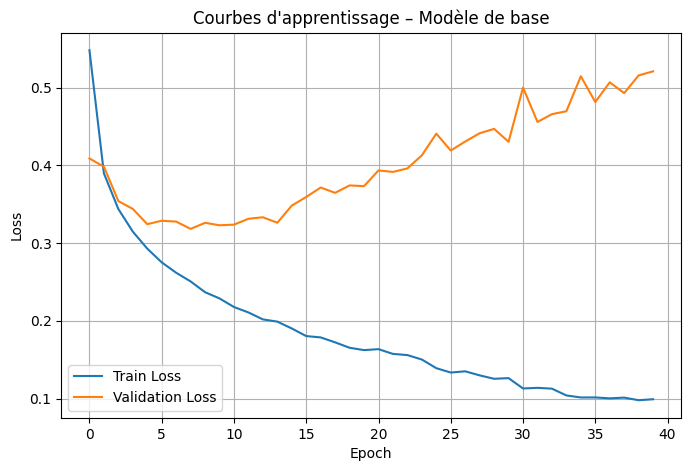

In [24]:
# Q5 - 1) Courbes d'apprentissage : train loss et validation loss
plt.figure(figsize=(8, 5))
plt.plot(history_baseline.history['loss'],     label='Train Loss')
plt.plot(history_baseline.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Courbes d\'apprentissage – Modèle de base')
plt.legend()
plt.grid(True)
plt.show()


In [25]:
# Q5 - 2) Évaluation sur l'ensemble de test
test_loss_base, test_accuracy_base = model_baseline.evaluate(X_test, y_test, verbose=0)
print('Test Loss     :', round(test_loss_base, 4))
print('Test Accuracy :', round(test_accuracy_base, 4))

Test Loss     : 0.5842
Test Accuracy : 0.8859


In [26]:
# Q5 - 3) Prédiction des classes sur l'ensemble de test
y_pred_proba = model_baseline.predict(X_test)
y_pred_base  = np.argmax(y_pred_proba, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


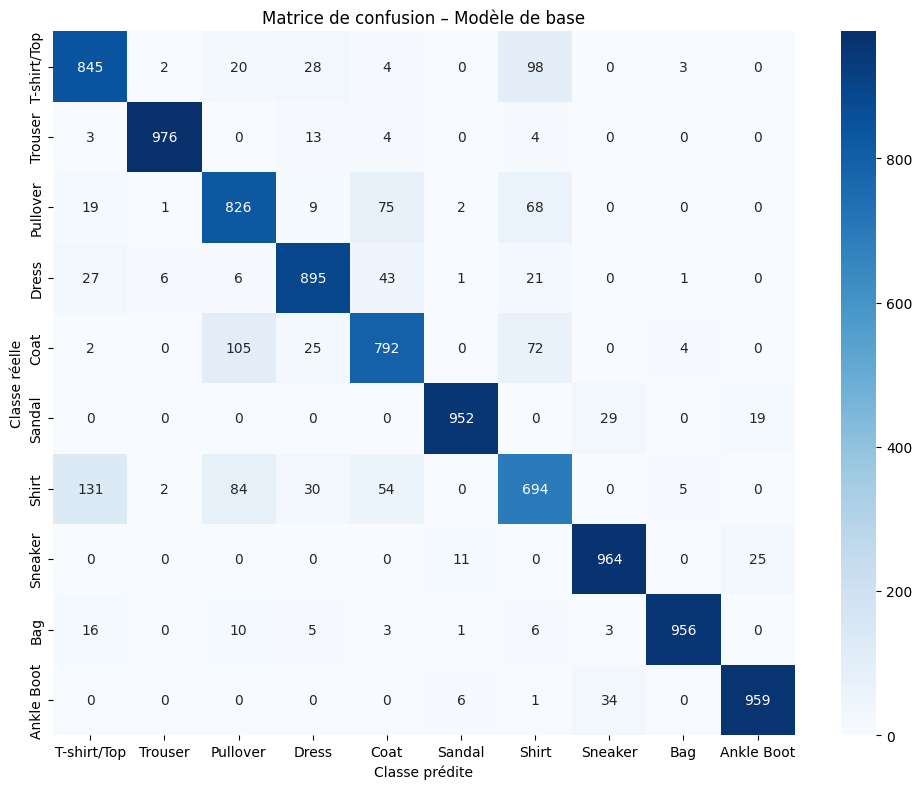


--- Analyse One-vs-Rest pour la classe 0 (T-shirt/top) ---
  T-shirt/Top     | TP= 845  FN= 155  FP= 198  TN= 8802
  Trouser         | TP= 976  FN=  24  FP=  11  TN= 8989
  Pullover        | TP= 826  FN= 174  FP= 225  TN= 8775
  Dress           | TP= 895  FN= 105  FP= 110  TN= 8890
  Coat            | TP= 792  FN= 208  FP= 183  TN= 8817
  Sandal          | TP= 952  FN=  48  FP=  21  TN= 8979
  Shirt           | TP= 694  FN= 306  FP= 270  TN= 8730
  Sneaker         | TP= 964  FN=  36  FP=  66  TN= 8934
  Bag             | TP= 956  FN=  44  FP=  13  TN= 8987
  Ankle Boot      | TP= 959  FN=  41  FP=  44  TN= 8956


In [27]:
# Q5 - 4) Matrice de confusion
cm_base = confusion_matrix(y_test, y_pred_base)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Classe prédite')
plt.ylabel('Classe réelle')
plt.title('Matrice de confusion – Modèle de base')
plt.tight_layout()
plt.show()

# Analyse one-vs-rest pour une classe exemple (classe 0 : T-shirt/top)
print('\n--- Analyse One-vs-Rest pour la classe 0 (T-shirt/top) ---')
for i, name in enumerate(class_names):
    TP = cm_base[i, i]
    FN = cm_base[i, :].sum() - TP
    FP = cm_base[:, i].sum() - TP
    TN = cm_base.sum() - TP - FN - FP
    print(f'  {name:15s} | TP={TP:4d}  FN={FN:4d}  FP={FP:4d}  TN={TN:5d}')

In [29]:
# Q5 - 5) Rapport de classification
class_names=['T-shirt/Top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle Boot']
print('Rapport de classification – Modèle de base :')
print(classification_report(y_test, y_pred_base, target_names=class_names))

Rapport de classification – Modèle de base :
              precision    recall  f1-score   support

 T-shirt/Top       0.81      0.84      0.83      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.79      0.83      0.81      1000
       Dress       0.89      0.90      0.89      1000
        Coat       0.81      0.79      0.80      1000
      Sandal       0.98      0.95      0.97      1000
       Shirt       0.72      0.69      0.71      1000
     Sneaker       0.94      0.96      0.95      1000
         Bag       0.99      0.96      0.97      1000
  Ankle Boot       0.96      0.96      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



---
## Q6 – Régularisation par Early Stopping

In [30]:
# Q6 - Modèle avec Early Stopping
model_early = Sequential([
    Dense(256, activation='relu', input_shape=(784,)),
    Dense(128, activation='relu'),
    Dense(64,  activation='relu'),
    Dense(10,  activation='softmax')
])

model_early.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Callback Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Entraînement
history_early = model_early.fit(
    X_train_final, y_train_final,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

print(f"\nEntraînement stoppé à l'epoch : {len(history_early.history['loss'])}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.8058 - loss: 0.5534 - val_accuracy: 0.8559 - val_loss: 0.4034
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8575 - loss: 0.3898 - val_accuracy: 0.8451 - val_loss: 0.4079
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8728 - loss: 0.3441 - val_accuracy: 0.8634 - val_loss: 0.3712
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8845 - loss: 0.3145 - val_accuracy: 0.8702 - val_loss: 0.3544
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8906 - loss: 0.2940 - val_accuracy: 0.8808 - val_loss: 0.3291
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8961 - loss: 0.2758 - val_accuracy: 0.8851 - val_loss: 0.3218
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9024 - loss: 0.2609 - val_accuracy: 0.8901 - val_loss: 0.3123
Epoch 8/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9075 - loss: 0.2468 - val_accuracy: 

---
## Q7 – Analyse du modèle avec Early Stopping

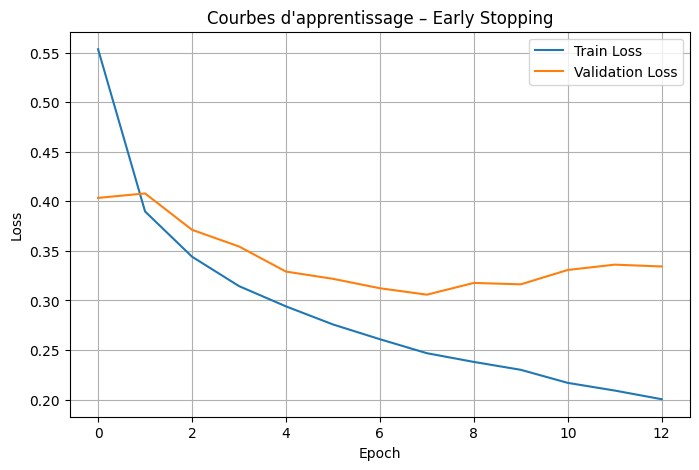

In [31]:
# Q7 - 1) Courbes d'apprentissage
plt.figure(figsize=(8, 5))
plt.plot(history_early.history['loss'],     label='Train Loss')
plt.plot(history_early.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Courbes d\'apprentissage – Early Stopping')
plt.legend()
plt.grid(True)
plt.show()

In [32]:
# Q7 - 2) Évaluation sur l'ensemble de test
test_loss_early, test_accuracy_early = model_early.evaluate(X_test, y_test, verbose=0)
print('Test Loss     (Early Stopping) :', round(test_loss_early, 4))
print('Test Accuracy (Early Stopping) :', round(test_accuracy_early, 4))

Test Loss     (Early Stopping) : 0.3327
Test Accuracy (Early Stopping) : 0.8836


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


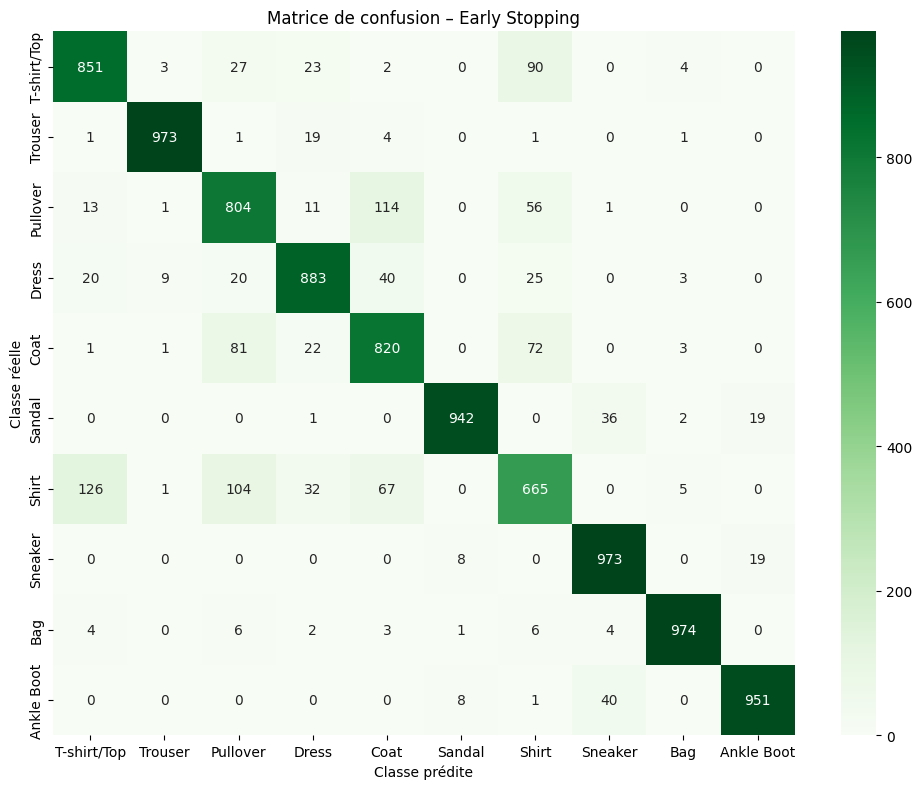

In [33]:
# Q7 - 3) Matrice de confusion
y_pred_early = np.argmax(model_early.predict(X_test), axis=1)
cm_early = confusion_matrix(y_test, y_pred_early)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_early, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Classe prédite')
plt.ylabel('Classe réelle')
plt.title('Matrice de confusion – Early Stopping')
plt.tight_layout()
plt.show()

In [34]:
# Q7 - 4) Rapport de classification
print('Rapport de classification – Early Stopping :')
print(classification_report(y_test, y_pred_early, target_names=class_names))

Rapport de classification – Early Stopping :
              precision    recall  f1-score   support

 T-shirt/Top       0.84      0.85      0.84      1000
     Trouser       0.98      0.97      0.98      1000
    Pullover       0.77      0.80      0.79      1000
       Dress       0.89      0.88      0.89      1000
        Coat       0.78      0.82      0.80      1000
      Sandal       0.98      0.94      0.96      1000
       Shirt       0.73      0.67      0.69      1000
     Sneaker       0.92      0.97      0.95      1000
         Bag       0.98      0.97      0.98      1000
  Ankle Boot       0.96      0.95      0.96      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



---
## Q8 – Régularisation par pénalisation des poids (L1, L2, Elastic Net)

In [36]:
# Q8 - Modèle avec régularisation L1 (λ = 0.001)
model_l1 = Sequential([
    Dense(256, activation='relu', input_shape=(784,), kernel_regularizer=l1(0.001)),
    Dense(128, activation='relu', kernel_regularizer=l1(0.001)),
    Dense(64,  activation='relu', kernel_regularizer=l1(0.001)),
    Dense(10,  activation='softmax')
])
model_l1.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_l1 = model_l1.fit(
    X_train_final, y_train_final,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=128,
    verbose=1
)

Epoch 1/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.7610 - loss: 3.1408 - val_accuracy: 0.7892 - val_loss: 1.5153
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.8071 - loss: 1.2729 - val_accuracy: 0.8182 - val_loss: 1.0950
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8161 - loss: 1.0332 - val_accuracy: 0.8252 - val_loss: 0.9405
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8210 - loss: 0.9212 - val_accuracy: 0.8342 - val_loss: 0.8524
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8248 - loss: 0.8531 - val_accuracy: 0.8382 - val_loss: 0.7980
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8282 - loss: 0.8090 - val_accuracy: 0.8404 - val_loss: 0.7640
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8309 - loss: 0.7771 - val_accuracy: 0.8425 - val_loss: 0.7372
Epoch 8/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8330 - loss: 0.7529 - val_accurac

In [37]:
# Q8 - Modèle avec régularisation L2 (λ = 0.001)
model_l2 = Sequential([
    Dense(256, activation='relu', input_shape=(784,), kernel_regularizer=l2(0.001)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(64,  activation='relu', kernel_regularizer=l2(0.001)),
    Dense(10,  activation='softmax')
])
model_l2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_l2 = model_l2.fit(
    X_train_final, y_train_final,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=128,
    verbose=1
)

Epoch 1/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.8011 - loss: 0.9549 - val_accuracy: 0.8428 - val_loss: 0.7276
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8496 - loss: 0.6694 - val_accuracy: 0.8512 - val_loss: 0.6305
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8584 - loss: 0.5897 - val_accuracy: 0.8478 - val_loss: 0.5928
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8642 - loss: 0.5451 - val_accuracy: 0.8553 - val_loss: 0.5556
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8685 - loss: 0.5133 - val_accuracy: 0.8587 - val_loss: 0.5267
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8718 - loss: 0.4922 - val_accuracy: 0.8552 - val_loss: 0.5248
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8740 - loss: 0.4753 - val_accuracy: 0.8597 - val_loss: 0.5023
Epoch 8/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8772 - loss: 0.4615 - val_accuracy:

In [38]:
# Q8 - Modèle Elastic Net (L1+L2 : λ1=0.0001, λ2=0.001)
model_elastic = Sequential([
    Dense(256, activation='relu', input_shape=(784,), kernel_regularizer=l1_l2(l1=0.0001, l2=0.001)),
    Dense(128, activation='relu', kernel_regularizer=l1_l2(l1=0.0001, l2=0.001)),
    Dense(64,  activation='relu', kernel_regularizer=l1_l2(l1=0.0001, l2=0.001)),
    Dense(10,  activation='softmax')
])
model_elastic.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_elastic = model_elastic.fit(
    X_train_final, y_train_final,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=128,
    verbose=1
)

Epoch 1/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7922 - loss: 1.4242 - val_accuracy: 0.8388 - val_loss: 0.9923
Epoch 2/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8391 - loss: 0.8899 - val_accuracy: 0.8477 - val_loss: 0.7936
Epoch 3/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8455 - loss: 0.7550 - val_accuracy: 0.8523 - val_loss: 0.7051
Epoch 4/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8512 - loss: 0.6839 - val_accuracy: 0.8517 - val_loss: 0.6624
Epoch 5/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8566 - loss: 0.6360 - val_accuracy: 0.8520 - val_loss: 0.6275
Epoch 6/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8589 - loss: 0.6030 - val_accuracy: 0.8529 - val_loss: 0.5999
Epoch 7/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8619 - loss: 0.5777 - val_accuracy: 0.8537 - val_loss: 0.5847
Epoch 8/40
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8645 - loss: 0.5571 - val_accuracy

---
## Q9 – Analyse des modèles régularisés

In [41]:
# Fonction utilitaire pour tracer les courbes de loss
def plot_learning_curves(history, title, color='blue'):
    plt.figure(figsize=(8, 5))
    plt.plot(history.history['loss'],     label='Train Loss',      color=color)
    plt.plot(history.history['val_loss'], label='Validation Loss', color=color, linestyle='--')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

# Fonction utilitaire pour la matrice de confusion
def plot_confusion_matrix(y_true, y_pred, title, cmap='Oranges'):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Classe prédite')
    plt.ylabel('Classe réelle')
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return cm

MODÈLE L1


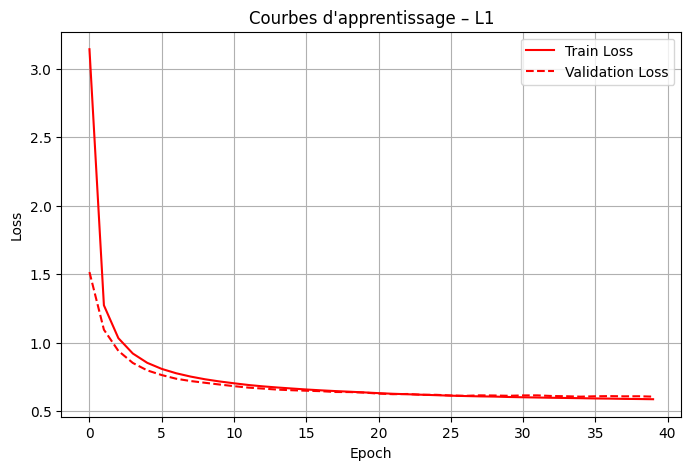

Test Loss (L1)     : 0.6410
Test Accuracy (L1) : 0.8300
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


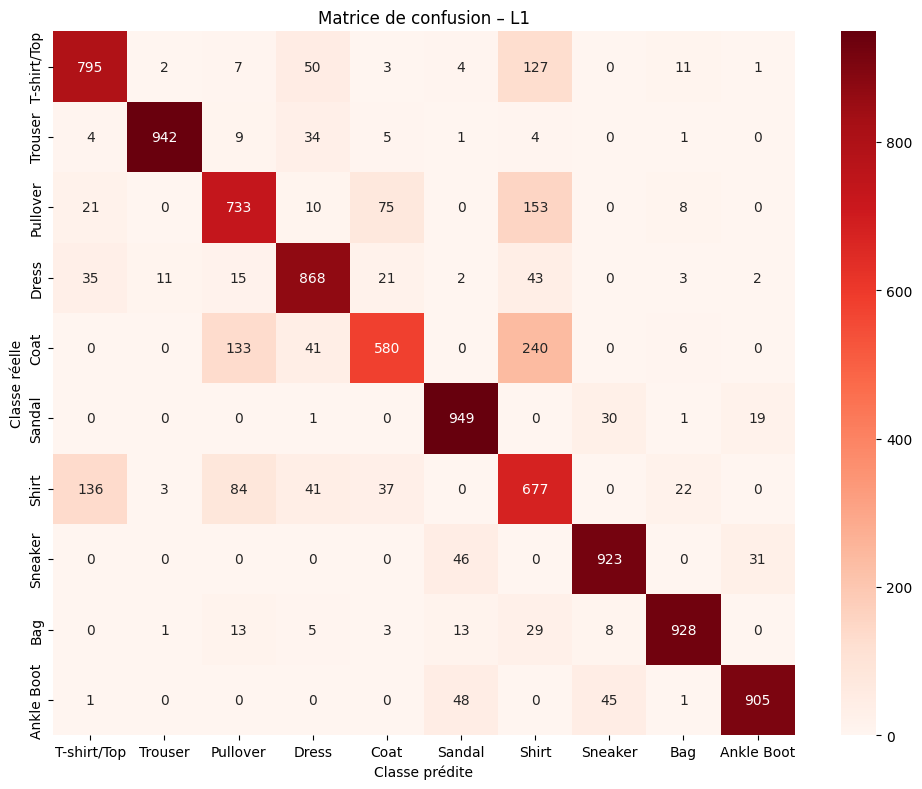

Rapport de classification – L1 :
              precision    recall  f1-score   support

 T-shirt/Top       0.80      0.80      0.80      1000
     Trouser       0.98      0.94      0.96      1000
    Pullover       0.74      0.73      0.74      1000
       Dress       0.83      0.87      0.85      1000
        Coat       0.80      0.58      0.67      1000
      Sandal       0.89      0.95      0.92      1000
       Shirt       0.53      0.68      0.60      1000
     Sneaker       0.92      0.92      0.92      1000
         Bag       0.95      0.93      0.94      1000
  Ankle Boot       0.94      0.91      0.92      1000

    accuracy                           0.83     10000
   macro avg       0.84      0.83      0.83     10000
weighted avg       0.84      0.83      0.83     10000



In [42]:
# ----- Modèle L1 -----
print('=' * 50)
print('MODÈLE L1')
print('=' * 50)

# 1) Courbes
plot_learning_curves(history_l1, 'Courbes d\'apprentissage – L1', color='red')

# 2) Évaluation
test_loss_l1, test_accuracy_l1 = model_l1.evaluate(X_test, y_test, verbose=0)
print(f'Test Loss (L1)     : {test_loss_l1:.4f}')
print(f'Test Accuracy (L1) : {test_accuracy_l1:.4f}')

# 3) Prédictions
y_pred_l1 = np.argmax(model_l1.predict(X_test), axis=1)

# 4) Matrice de confusion
plot_confusion_matrix(y_test, y_pred_l1, 'Matrice de confusion – L1', cmap='Reds')

# 5) Rapport de classification
print('Rapport de classification – L1 :')
print(classification_report(y_test, y_pred_l1, target_names=class_names))

MODÈLE L2


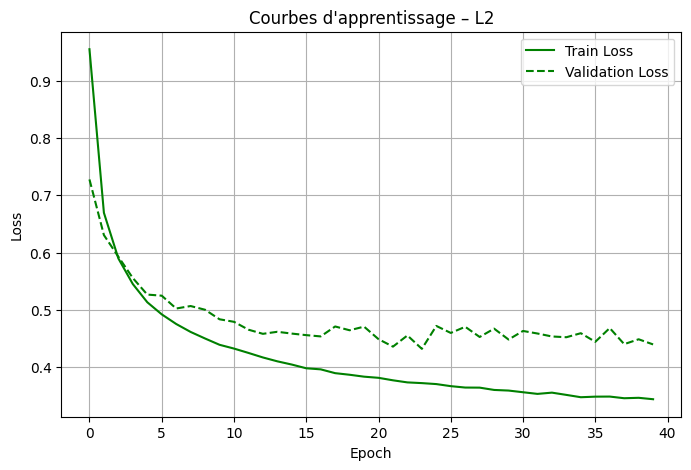

Test Loss (L2)     : 0.4777
Test Accuracy (L2) : 0.8595
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


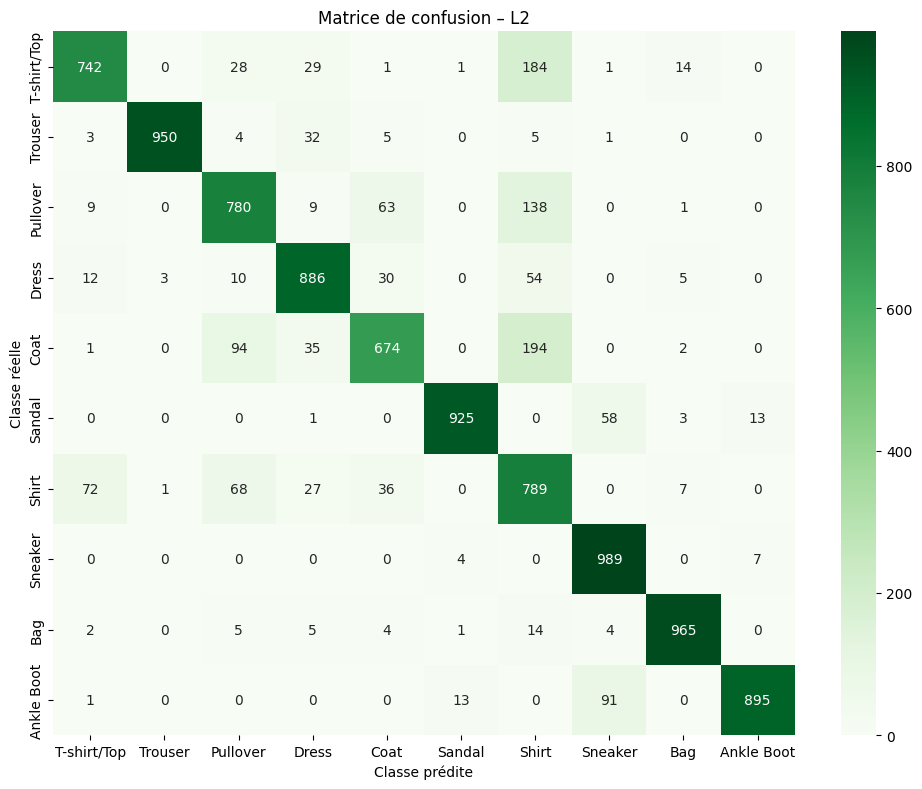

Rapport de classification – L2 :
              precision    recall  f1-score   support

 T-shirt/Top       0.88      0.74      0.81      1000
     Trouser       1.00      0.95      0.97      1000
    Pullover       0.79      0.78      0.78      1000
       Dress       0.87      0.89      0.88      1000
        Coat       0.83      0.67      0.74      1000
      Sandal       0.98      0.93      0.95      1000
       Shirt       0.57      0.79      0.66      1000
     Sneaker       0.86      0.99      0.92      1000
         Bag       0.97      0.96      0.97      1000
  Ankle Boot       0.98      0.90      0.93      1000

    accuracy                           0.86     10000
   macro avg       0.87      0.86      0.86     10000
weighted avg       0.87      0.86      0.86     10000



In [43]:
# ----- Modèle L2 -----
print('=' * 50)
print('MODÈLE L2')
print('=' * 50)

# 1) Courbes
plot_learning_curves(history_l2, 'Courbes d\'apprentissage – L2', color='green')

# 2) Évaluation
test_loss_l2, test_accuracy_l2 = model_l2.evaluate(X_test, y_test, verbose=0)
print(f'Test Loss (L2)     : {test_loss_l2:.4f}')
print(f'Test Accuracy (L2) : {test_accuracy_l2:.4f}')

# 3) Prédictions
y_pred_l2 = np.argmax(model_l2.predict(X_test), axis=1)

# 4) Matrice de confusion
plot_confusion_matrix(y_test, y_pred_l2, 'Matrice de confusion – L2', cmap='Greens')

# 5) Rapport de classification
print('Rapport de classification – L2 :')
print(classification_report(y_test, y_pred_l2, target_names=class_names))

MODÈLE ELASTIC NET (L1+L2)


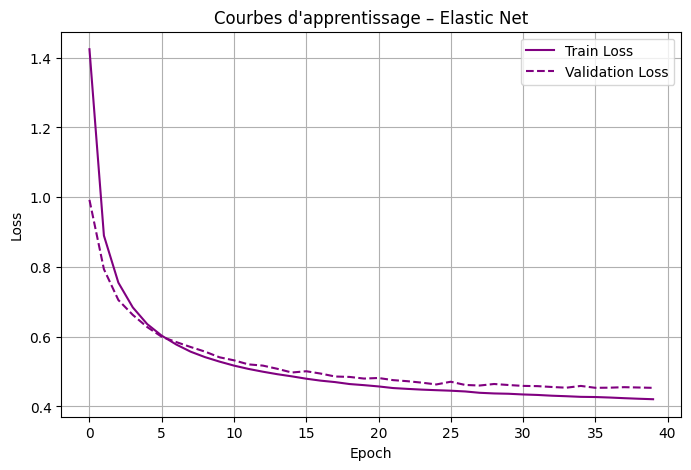

Test Loss (Elastic Net)     : 0.4878
Test Accuracy (Elastic Net) : 0.8679
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


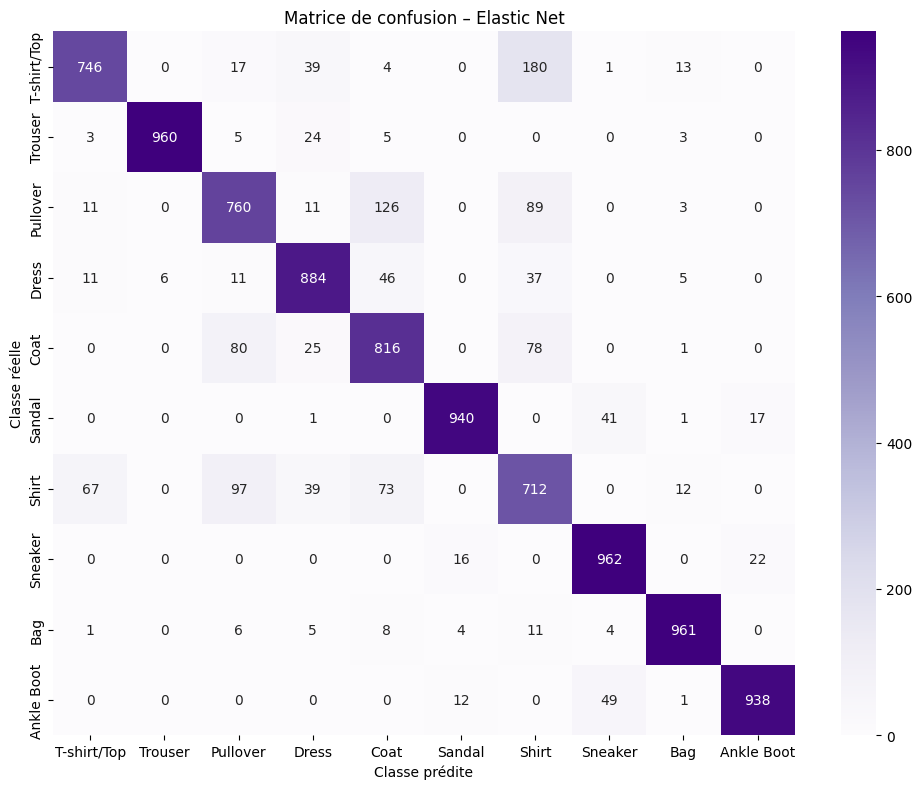

Rapport de classification – Elastic Net :
              precision    recall  f1-score   support

 T-shirt/Top       0.89      0.75      0.81      1000
     Trouser       0.99      0.96      0.98      1000
    Pullover       0.78      0.76      0.77      1000
       Dress       0.86      0.88      0.87      1000
        Coat       0.76      0.82      0.79      1000
      Sandal       0.97      0.94      0.95      1000
       Shirt       0.64      0.71      0.68      1000
     Sneaker       0.91      0.96      0.94      1000
         Bag       0.96      0.96      0.96      1000
  Ankle Boot       0.96      0.94      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



In [44]:
# ----- Modèle Elastic Net -----
print('=' * 50)
print('MODÈLE ELASTIC NET (L1+L2)')
print('=' * 50)

# 1) Courbes
plot_learning_curves(history_elastic, 'Courbes d\'apprentissage – Elastic Net', color='purple')

# 2) Évaluation
test_loss_elastic, test_accuracy_elastic = model_elastic.evaluate(X_test, y_test, verbose=0)
print(f'Test Loss (Elastic Net)     : {test_loss_elastic:.4f}')
print(f'Test Accuracy (Elastic Net) : {test_accuracy_elastic:.4f}')

# 3) Prédictions
y_pred_elastic = np.argmax(model_elastic.predict(X_test), axis=1)

# 4) Matrice de confusion
plot_confusion_matrix(y_test, y_pred_elastic, 'Matrice de confusion – Elastic Net', cmap='Purples')

# 5) Rapport de classification
print('Rapport de classification – Elastic Net :')
print(classification_report(y_test, y_pred_elastic, target_names=class_names))

**Commentaire Q9 :**
- **L1** : pousse certains poids exactement à zéro (sparsité) ; peut parfois réduire la capacité du modèle. Moins performant que L2 sur des données denses comme Fashion-MNIST.
- **L2** : pénalise les poids de grande amplitude sans les annuler ; généralement plus stable et performant que L1.
- **Elastic Net** : combine les avantages de L1 (sparsité) et L2 (stabilité). Offre un bon compromis.

---
## Q10 – Aide à la décision : Tableau comparatif et conclusion

In [45]:
import pandas as pd

# Création du tableau comparatif
results = pd.DataFrame({
    'Model': ['Baseline', 'EarlyStopping', 'L1', 'L2', 'ElasticNet'],
    'Test Loss': [
        test_loss_base,
        test_loss_early,
        test_loss_l1,
        test_loss_l2,
        test_loss_elastic
    ],
    'Test Accuracy': [
        test_accuracy_base,
        test_accuracy_early,
        test_accuracy_l1,
        test_accuracy_l2,
        test_accuracy_elastic
    ]
})

results['Test Loss']     = results['Test Loss'].round(4)
results['Test Accuracy'] = results['Test Accuracy'].round(4)

print(results.to_string(index=False))

        Model  Test Loss  Test Accuracy
     Baseline     0.5842         0.8859
EarlyStopping     0.3327         0.8836
           L1     0.6410         0.8300
           L2     0.4777         0.8595
   ElasticNet     0.4878         0.8679


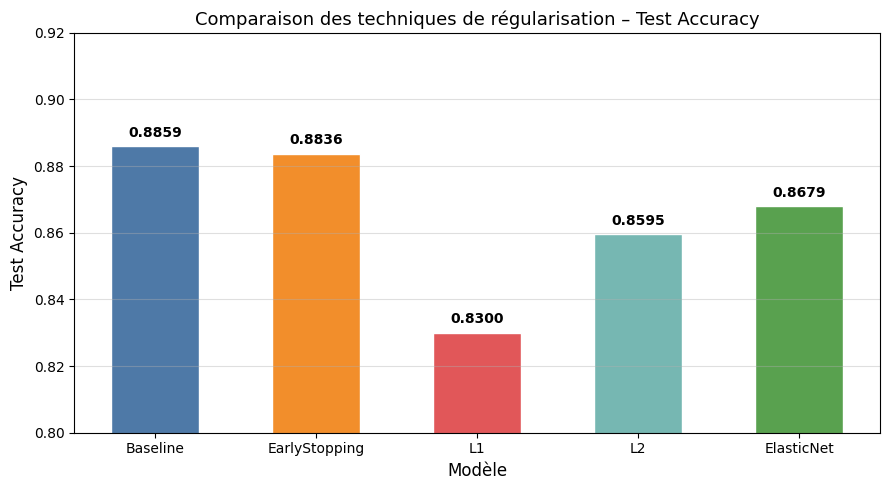

In [46]:
# Graphique de comparaison des accuracies
colors = ['#4e79a7', '#f28e2b', '#e15759', '#76b7b2', '#59a14f']

plt.figure(figsize=(9, 5))
bars = plt.bar(results['Model'], results['Test Accuracy'], color=colors, width=0.55, edgecolor='white')

# Afficher les valeurs au-dessus des barres
for bar, val in zip(bars, results['Test Accuracy']):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.002,
             f'{val:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.xlabel('Modèle', fontsize=12)
plt.ylabel('Test Accuracy', fontsize=12)
plt.title('Comparaison des techniques de régularisation – Test Accuracy', fontsize=13)
plt.ylim(0.8, 0.92)
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()